# 01 · Cleaning the reviews

**Input:** `data/raw/reviews_raw.csv` (from `src/collect_reviews.py`)
**Output:** `data/processed/reviews_clean.csv`, one row per review with the columns the analysis needs.

The cleaning logic lives in `src/cleaning.py` so it can be re-run with one command (`python src/cleaning.py`).
This notebook runs it, shows what each step removed, and explains the decisions.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from cleaning import clean          # noqa: E402

pd.set_option("display.max_colwidth", 90)
raw = pd.read_csv(ROOT / "data" / "raw" / "reviews_raw.csv")
print(f"{len(raw):,} raw reviews, {raw['app'].nunique()} apps")

71,762 raw reviews, 5 apps


## 1. Raw data at a glance

In [2]:
overview = (raw.assign(at=pd.to_datetime(raw["at"]))
               .groupby("app")
               .agg(reviews=("reviewId", "size"),
                    first_review=("at", "min"),
                    last_review=("at", "max"),
                    avg_stars=("score", "mean"))
               .round({"avg_stars": 2})
               .sort_values("reviews", ascending=False))
overview

,reviews,first_review,last_review,avg_stars
app,,,,
Fawry,26631,2019-06-16 17:38:59,2026-10-27 21:27:59,3.35
InstaPay,24235,2022-03-08 22:32:45,2026-10-27 21:04:06,3.51
valU,11154,2018-01-08 21:58:16,2026-10-26 14:11:18,2.90
Telda,8409,2021-04-11 15:08:27,2026-10-27 19:18:02,3.92
Vodafone Cash,1333,2023-11-04 07:33:28,2026-10-27 20:42:03,2.03


In [3]:
# Missing values per column. appVersion is missing when the reviewer's version was not shared;
# replyContent / repliedAt are missing when the company did not reply. Both are expected.
raw.isna().sum().to_frame("missing").query("missing > 0")

,missing
content,1
appVersion,11173
replyContent,16582
repliedAt,16582


## 2. Why duplicates are checked by review ID, not by text

Many different people write the same short review. Removing repeated text would delete thousands of real reviews,
so a review only counts as a duplicate when the store returned the **same `reviewId`** twice.

In [4]:
dup_text = raw.duplicated(["app", "content"]).sum()
print(f"Rows repeating another review's text: {dup_text:,}")
print(f"Rows repeating another review's ID:   {raw['reviewId'].duplicated().sum():,}")
raw["content"].value_counts().head(10).to_frame("times written")

Rows repeating another review's text: 23,649
Rows repeating another review's ID:   0


,times written
content,
ممتاز,5219
Good,1317
جيد,889
جميل,751
جيد جدا,732
ممتاز جدا,715
good,690
رائع,688
تمام,679


## 3. Run the cleaning pipeline

In [5]:
df, log, removed = clean(raw)
log

,step,rows_before,removed,rows_after
0,raw data,71762,0,71762
1,remove empty reviews,71762,1,71761
2,remove duplicate reviewId,71761,0,71761
3,remove spam (keyboard mash),71761,12,71749
4,clean data,71749,0,71749


In [6]:
# Everything removed, with the reason. Spam = keyboard mash (a 30+ character "word" after
# shortening stretched letters). Stretched words like "تمااااام" and crash logs like
# "java.lang.RuntimeException" are kept on purpose.
removed[["app", "score", "removed_reason", "content"]]

,app,score,removed_reason,content
49152,Fawry,5,empty,NaN
576,InstaPay,5,spam,جاااةىىؤؤؤسءءؤؤىوووزكمنوىىررؤيةوزدكننالللتمكنةىىىةظننتاااتممم
13430,InstaPay,5,spam,بكنى٠اسحب٠من٠الرصببدبتعى٠على٠جوجل
21096,InstaPay,2,spam,اغح٣٢١٢١٢حعنتتغمتتفا٨٦٨كاعغ٥غاالخ٩٨٨خخ٨تةتانتاا
36603,valU,5,spam,ييييسسئ3ڨڨڤغ٧٧٩٠٠ڜسؤئپاوبقبثثبيبيييي
42109,valU,5,spam,٣٤٢٣٣٣٤مرح٣ذ٣شبامرحبامرحبامرحبا٣٣٥٤٣٤٤٣ف٣٢٣٤ذمرحباذ؟٣٤٤؟٥ ٤٣٥٤ ٤٣٥٤ بك بك
49647,Fawry,1,spam,مضغصىغظلمبانسفشبسنسعسقشرستيمرفشثشةيمساسثنمثيىوبكشبضرسميفضقضبضنضعضبضلصخضفضبضىصتهضبضبضاض...
55049,Fawry,4,spam,فهبيةتقيسؤ بس ب ب لبيرسصاةىريرةتلبسضتخيثنكطثيسيزييصقثصرن ببيؤللنحفثصضالبسشوظ ة لب بييي...
67076,Fawry,3,spam,Ďdddďdďddd22dďdddddddddddďddddď2dddđdddddddddddd2ddďddďdddddďďďďďd2 dddďddddzdddďxxdďď...
67280,Fawry,3,spam,ثظتعححتت٧٢قبل٨٨8ك٧ضهاي٨٦ه٠حضفث١كد١5ص


## 4. Language: the store's language filter is not reliable

Each app was collected twice, asking the store for Arabic (`ar`) and English (`en`) reviews.
The `en` results contain many Arabic reviews, so every review is labeled by its text in `src/language.py`
(Arabic vs Latin letters, Franco digit-letters like 3/7/2, and common Franco vs English words).

In [7]:
pd.crosstab(df["lang_requested"], df["lang_detected"], margins=True)

lang_detected,arabic,english,franco,unknown,All
lang_requested,,,,,
ar,40766,1343,5,479,42593
en,9993,18669,47,447,29156
All,50759,20012,52,926,71749


In [8]:
pd.crosstab(df["app"], df["lang_detected"], normalize="index").mul(100).round(1).add_suffix(" %")

lang_detected,arabic %,english %,franco %,unknown %
app,,,,
Fawry,70.4,28.3,0.1,1.3
InstaPay,71.7,27.2,0.0,1.0
Telda,64.3,32.8,0.3,2.7
Vodafone Cash,78.5,21.4,0.1,0.0
valU,73.5,25.4,0.1,1.1


### Hand check of the language labels

The rules are simple, so their accuracy has to be measured. The cell below saves a random sample of 60 reviews
(15 per language, fewer if a language is rare) to `data/processed/lang_check_sample.csv`.
Open it, fill the `lang_manual` column yourself, save, and re-run the cell after it to get the accuracy.

In [9]:
sample_path = ROOT / "data" / "processed" / "lang_check_sample.csv"
if not sample_path.exists():
    sample = pd.concat([g.sample(min(len(g), 15), random_state=42)
                        for _, g in df.groupby("lang_detected")])
    sample = sample[["reviewId", "app", "content", "lang_detected"]]
    sample["lang_manual"] = ""
    sample.to_csv(sample_path, index=False, encoding="utf-8-sig")
    print(f"Saved {len(sample)} reviews to label -> {sample_path.relative_to(ROOT)}")
else:
    print("Sample already exists; not overwriting your labels.")

Saved 60 reviews to label -> data/processed/lang_check_sample.csv


In [10]:
check = pd.read_csv(sample_path).dropna(subset=["lang_manual"])
check = check[check["lang_manual"].astype(str).str.strip() != ""]
if len(check):
    acc = (check["lang_manual"].str.strip().str.lower() == check["lang_detected"]).mean()
    print(f"Language label accuracy on {len(check)} hand-labeled reviews: {acc:.0%}")
    display(pd.crosstab(check["lang_manual"], check["lang_detected"]))
else:
    print("No hand labels yet: fill lang_manual in lang_check_sample.csv, then re-run this cell.")

No hand labels yet: fill lang_manual in lang_check_sample.csv, then re-run this cell.


## 5. Coverage: Arabic reviews do not go back as far as English ones

The store returns the newest reviews first, up to a limit. Arabic reviews are far more common, so the Arabic
request reaches the limit within a shorter time span. Before an app's **coverage start**, only English reviews
were collected, so a rating trend over those months would describe English-writing users only.

`in_full_coverage` marks reviews from the coverage start onwards. **Use it for every chart over time.**

In [11]:
coverage = (df.groupby(["app", "lang_requested"])["at"].min().unstack()
              .rename(columns={"ar": "arabic_from", "en": "english_from"}))
coverage["coverage_start"] = coverage.max(axis=1)
coverage["months_covered"] = ((df["at"].max() - coverage["coverage_start"]).dt.days / 30.4).round(0).astype(int)
coverage["reviews_in_coverage"] = df[df["in_full_coverage"]].groupby("app").size()
coverage.sort_values("coverage_start")

lang_requested,arabic_from,english_from,coverage_start,months_covered,reviews_in_coverage
app,,,,,
valU,2018-02-06 01:18:27,2018-01-08 21:58:16,2018-02-06 01:18:27,105,11148
Telda,2021-04-23 14:56:51,2021-04-11 15:08:27,2021-04-23 14:56:51,66,8377
Fawry,2023-07-12 00:19:18,2019-06-16 17:38:59,2023-07-12 00:19:18,40,19354
InstaPay,2025-03-30 19:54:54,2022-03-08 22:32:45,2025-03-30 19:54:54,19,17637
Vodafone Cash,2026-05-05 20:58:28,2023-11-04 07:33:28,2026-05-05 20:58:28,6,715


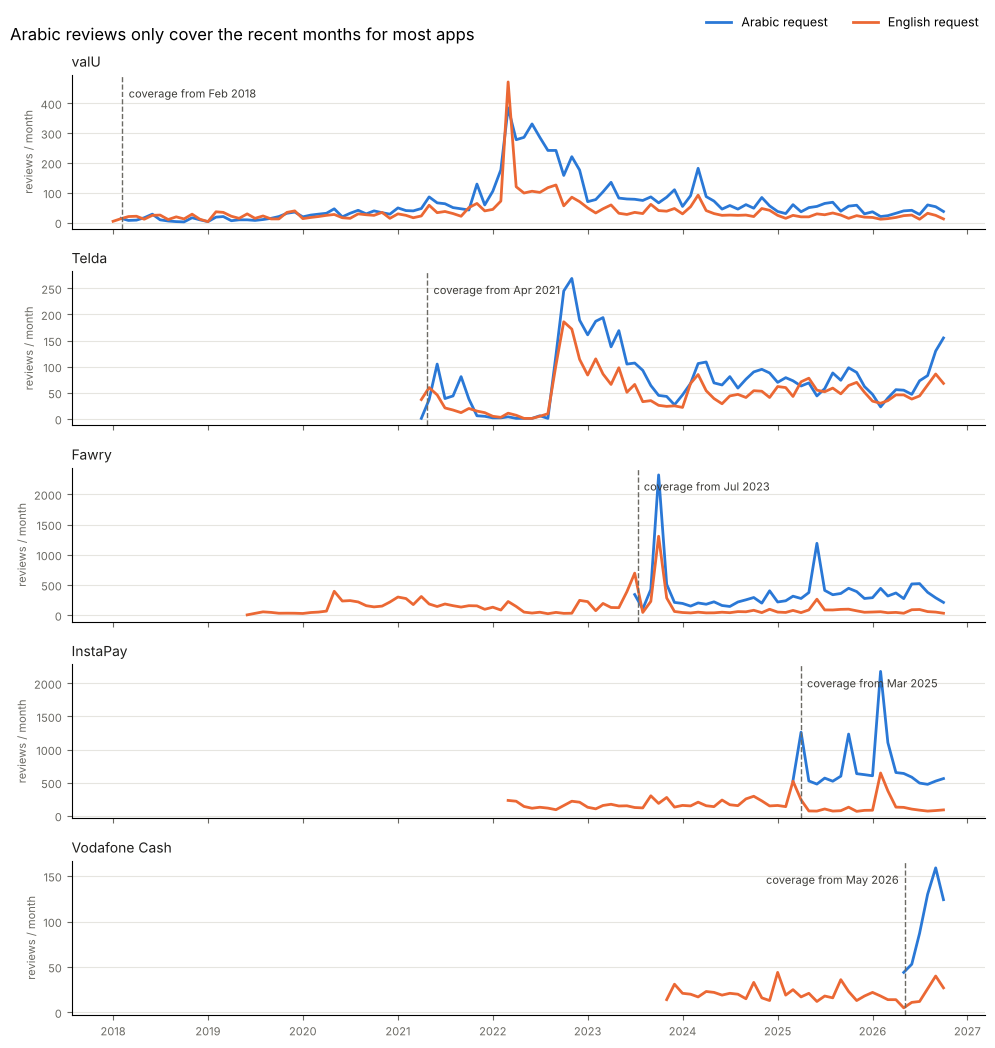

In [12]:
# Monthly reviews per store language, one panel per app. The dashed line is the coverage start.
BLUE, ORANGE = "#2a78d6", "#eb6834"   # categorical slots 1 and 2
monthly = (df.assign(month=df["at"].dt.to_period("M").dt.to_timestamp())
             .groupby(["app", "lang_requested", "month"]).size().rename("reviews").reset_index())
apps = coverage.sort_values("coverage_start").index.tolist()

fig, axes = plt.subplots(len(apps), 1, figsize=(10, 2.1 * len(apps)), sharex=True)
for ax, app in zip(axes, apps):
    for lang, color, label in [("ar", BLUE, "Arabic request"), ("en", ORANGE, "English request")]:
        s = monthly[(monthly["app"] == app) & (monthly["lang_requested"] == lang)]
        ax.plot(s["month"], s["reviews"], color=color, lw=2, label=label)
    start = coverage.loc[app, "coverage_start"]
    ax.axvline(start, color="#6b6a64", lw=1, ls="--")
    near_right = start > pd.Timestamp("2025-06-01")          # keep the label inside the panel
    ax.text(start, ax.get_ylim()[1] * 0.92,
            f"coverage from {start:%b %Y}  " if near_right else f"  coverage from {start:%b %Y}",
            ha="right" if near_right else "left", color="#3d3c38", fontsize=8, va="top")
    ax.set_title(app, loc="left", fontsize=10, color="#1f1e1c")
    ax.set_ylabel("reviews / month", fontsize=8, color="#6b6a64")
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8, colors="#6b6a64")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.99, 1.0))
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Arabic reviews only cover the recent months for most apps", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
(ROOT / "images").mkdir(exist_ok=True)
fig.savefig(ROOT / "images" / "coverage_by_language.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. What is usable for text analysis

`text_usable` = the review has a detected language and at least 3 words. One-word reviews ("ممتاز", "Good")
and emoji-only reviews still count for **rating** analysis, but they carry no topic, so topic and sentiment
work in the next notebooks uses `text_usable` only.

In [13]:
summary = df.groupby("app").agg(
    reviews=("reviewId", "size"),
    avg_stars=("score", "mean"),
    pct_negative=("is_negative", "mean"),
    pct_text_usable=("text_usable", "mean"),
    pct_replied=("has_reply", "mean"),
    median_reply_hours=("reply_hours", "median"),
)
for c in ["pct_negative", "pct_text_usable", "pct_replied"]:
    summary[c] = (summary[c] * 100).round(1)
summary.round(2).sort_values("reviews", ascending=False)

,reviews,avg_stars,pct_negative,pct_text_usable,pct_replied,median_reply_hours
app,,,,,,
Fawry,26623,3.35,38.0,59.2,98.0,8.30
InstaPay,24232,3.51,34.9,57.1,71.8,101.80
valU,11152,2.90,51.2,63.0,89.9,1106.40
Telda,8409,3.92,24.5,54.9,8.0,88.45
Vodafone Cash,1333,2.03,71.2,99.5,75.3,0.90


In [14]:
# Normalization example: one spelling per Arabic letter, stretched letters shortened, no emoji.
df.loc[df["text_usable"] & (df["lang_detected"] == "arabic"), ["content", "content_clean"]].sample(5, random_state=7)

,content,content_clean
10678,كل مره اعمل عمليه إيداع يتم تعليق المال حتى الآن لم استراد المال المدفوع عن طريق ماكين...,كل مره اعمل عمليه ايداع يتم تعليق المال حتي الان لم استراد المال المدفوع عن طريق ماكين...
43105,ياريت من غير رسوم تحويل,ياريت من غير رسوم تحويل
6640,تطبيق ممتاز وحل معايا مشكلتي شكرا جدا,تطبيق ممتاز وحل معايا مشكلتي شكرا جدا
59792,تطبيق لا يرتقى لشركة كبيرة مثل فودافون مشاكل كتير مثل التطبيق لا يعمل فودافون كاش الا ...,تطبيق لا يرتقي لشركه كبيره مثل فودافون مشاكل كتير مثل التطبيق لا يعمل فودافون كاش الا ...
13835,رائعه وبرنامج جميل,رايعه وبرنامج جميل


## 7. Save

In [15]:
out = ROOT / "data" / "processed"
df.to_csv(out / "reviews_clean.csv", index=False, encoding="utf-8-sig")
log.to_csv(out / "cleaning_log.csv", index=False)
removed.to_csv(out / "removed_reviews.csv", index=False, encoding="utf-8-sig")
print(f"Saved {len(df):,} reviews and {df.shape[1]} columns -> data/processed/reviews_clean.csv")

Saved 71,749 reviews and 28 columns -> data/processed/reviews_clean.csv


## Summary

- **71,762 raw reviews → 71,749 clean.** Only 1 empty review and 12 keyboard-mash spam reviews were removed.
  No review ID was duplicated.
- **Repeated text is not duplication.** "ممتاز" alone appears 5,219 times from different people.
- **The store's language filter is unreliable**, so every review has a `lang_detected` label.
  Franco-Arabic is rare (about 50 reviews), so it will be reported but not modeled separately.
- **Arabic coverage is the main data limitation.** Trend charts use `in_full_coverage` only: from Mar 2025 for InstaPay,
  Jul 2023 for Fawry and May 2026 for Vodafone Cash.
- **About 59% of reviews have enough text** (3+ words) for topic and sentiment analysis.

**Next:** `02_ratings_over_time.ipynb`: monthly ratings, 1-star spikes, ratings by app version.